## Exercise 9-1: TOTO Jackpot Simulator

In [1]:
import time, random
random.seed(628)

In [65]:
# understand what is the difference between random.sample and random.choices
print(random.sample(range(1, 10), k = 6))
print(random.choices(range(1, 10), k = 6))

[3, 2, 1, 4, 7, 8]
[5, 1, 1, 1, 7, 5]


In [3]:
bet_type = ['quick_pick', 'system_7', 'system_8', 'system_9', 'system_10']
bet_type_prob = [0.877, 0.09, 0.0225, 0.0075, 0.003]
bet_cost = {'quick_pick': 1, 'system_7': 7, 'system_8': 28, 'system_9': 84, 'system_10': 210}
bet_number = {'quick_pick': 6, 'system_7': 7, 'system_8': 8, 'system_9': 9, 'system_10': 10}

In [4]:
def calculate_prize(num_list, winning_list):
    match_count, match_additional = 0, False
    for i in num_list:
        if winning_list[i] == 1:
            match_count += 1
        elif winning_list[i] == 2:
            match_additional = True
    if match_count == 6:
        return 1
    elif match_count >= 3:
        return 13 - 2 * match_count - match_additional # match at least 3 numbers, additoinal number considered half-match
    else:
        return 0

In [ ]:
#  13 - 2 * match_count - match_additional

# match_count  match_additional
#  6                             13 - 2*6    = 1
#  5           T                 13 - 2*5 -1 = 2
#  5           F                               3
#  4           T                               4
#  4           F                               5
#  3           T                               6
#  3           F                               7

In [66]:
# we may set up a very simple simulator on the distribution of prizes
trial, prize_distr = 1000000, {}
for _ in range(trial):
    my_bet_num = random.sample(range(1, 50), k = 6)
    winning_num = random.sample(range(1, 50), k = 7) # generate the 6 winning numbers plus the additional number
    winning_list = [0] * 50 # convert to list, for fast matching on any bet
    for i in winning_num[:-1]:
        winning_list[i] = 1
    winning_list[winning_num[-1]] = 2 # this is the additional number
    p = calculate_prize(my_bet_num, winning_list)
    prize_distr[p] = prize_distr.get(p, 0) + 1

for k, v in prize_distr.items():
    if k == 0:
        print('no prize: %.3f' % (v / trial))
    else:
        print('prize group %i: %.3f' % (k, v / trial))

no prize: 0.981
prize group 7: 0.016
prize group 6: 0.001
prize group 5: 0.001
prize group 3: 0.000
prize group 4: 0.000
prize group 1: 0.000
prize group 2: 0.000


In [73]:
prize_distr

{0: 981466, 7: 16362, 6: 1245, 5: 875, 3: 17, 4: 33, 1: 1, 2: 1}

In [67]:
my_bet_num

[28, 44, 9, 46, 41, 1]

In [69]:
len(winning_list)

50

In [71]:
winning_list[4]

0

In [68]:
winning_list

[0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 2,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [72]:
calculate_prize(my_bet_num, winning_list)

0

## Exercise 9-2: Area Estimation

In [81]:
import numpy as np
from scipy.spatial import ConvexHull

vertices = np.array([(3.81, 1.47), (3.72, 1.45), (3.67, 1.42), (3.62, 1.30),
                     (3.83, 1.26), (4.01, 1.31), (4.03, 1.36), (3.99, 1.39)])

# the vertices here are arranged anti-clockwise.

hull = ConvexHull(vertices)

num_vert, num_hull_vert = len(vertices), len(hull.vertices)

# usually num_vert and num_hull_vert are not equal.
# hull.vertices are vertices on the convex hull, and the convex hull is constructed from the entire set of vertices.

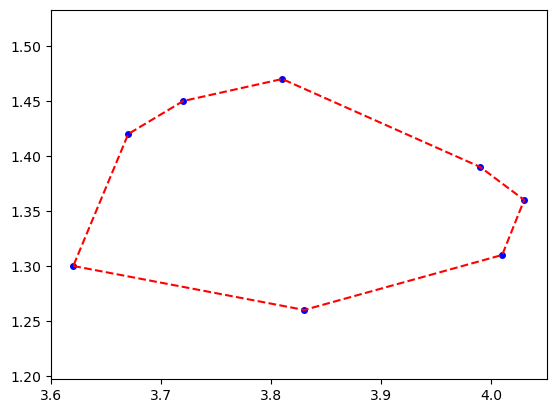

In [83]:
import matplotlib.pyplot as plt

boundary = np.append(hull.vertices, hull.vertices[0])
plt.plot(vertices[:, 0], vertices[:, 1], 'bo', ms = 4)
plt.plot(vertices[boundary, 0], vertices[boundary, 1], 'r--')

plt.axis('equal')
plt.show()

In [84]:
def determinant(px, p_fr, p_to):
    return px[0] * p_fr[1] + p_fr[0] * p_to[1] + p_to[0] * px[1] - px[1] * p_fr[0] - p_fr[1] * p_to[0] - p_to[1] * px[0]

def left_of_line(px, p_fr, p_to):
    return True if determinant(px, p_fr, p_to) > 0.0 else False

def on_the_line(px, p_fr, p_to):
    return True if determinant(px, p_fr, p_to) == 0.0 else False

def right_of_line(px, p_fr, p_to):
    return True if determinant(px, p_fr, p_to) < 0.0 else False

# if you'd like know more about this, please check on matrix determinant https://en.wikipedia.org/wiki/Curve_orientation

In [85]:
var = -5.1
True if var > 0 else False

False

In [86]:
# all([True, True, False, True])
all([True, True, True, True])

True

In [ ]:
print(hull.vertices)
len(hull.vertices)

# i:              0-1, 1-2, 2-3, 3-4
# boundary[i]:    3-4, 4-5, 5-6, 6-7, ...
# vertices[boundary[i]]    get the coordinates

[3 4 5 6 7 0 1 2]


8

In [ ]:
x_min, x_max = min(vertices[:, 0]), max(vertices[:, 0])
y_min, y_max = min(vertices[:, 1]), max(vertices[:, 1])

# we are to sample points in this bounding rectangle

import random
random.seed('20261028')
count_inside, total_sample = 0, 10000
for _ in range(total_sample):
    x_rand, y_rand = x_min + random.random() * (x_max - x_min), y_min + random.random() * (y_max - y_min)
    count_inside += all(
        [left_of_line((x_rand, y_rand), vertices[boundary[i]], vertices[boundary[i+1]]) for i in range(num_hull_vert)]
    )
    # if a point (x_rand, y_rand) is inside, it must be on the left of ALL line segments, each formed by vertices[boundary[i]] and vertices[boundary[i+1]]

## I am using `def left_of_line(px, p_fr, p_to)` from above
## px: (x_rand, y_rand)
## p_fr: vertices[boundary[i]]
## p_to: vertices[boundary[i+1]]
## all([..., ..., ...]) true if-and-only-if the point is interest is to the left of ALL arrows
    
print('the estimated area is %.3f km square.' % (count_inside / total_sample * (x_max - x_min) * (y_max - y_min) * 12309.1))

# suppose 1 unit square = (111.32 km X 110.574 km) = 12309.1 km^2
# Around the equator, one degree of longitude is about 111.320 km and one degree of latitude is about 110.574 km.

the estimated area is 702.338 km square.


**But a polygon is not always convex.**

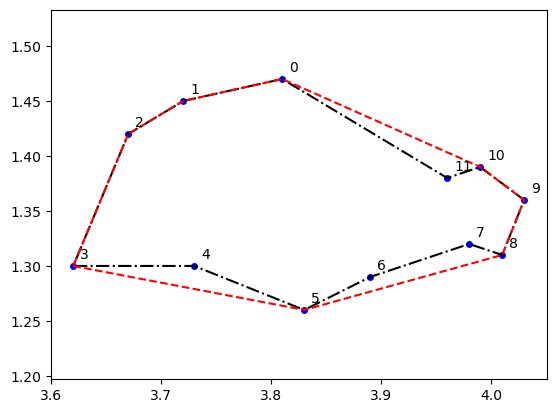

In [10]:
vertices = np.array([(3.81, 1.47), (3.72, 1.45), (3.67, 1.42), (3.62, 1.30), (3.73, 1.30), (3.83, 1.26),
                     (3.89, 1.29), (3.98, 1.32), (4.01, 1.31), (4.03, 1.36), (3.99, 1.39), (3.96, 1.38)])

hull = ConvexHull(vertices)
num_vert, num_hull_vert = len(vertices), len(hull.vertices)

boundary = list(np.append(hull.vertices, hull.vertices[0])) # this is the list of indices of vertices on the convex hull with first vertex repeated last
plt.plot(vertices[:, 0], vertices[:, 1], 'bo', ms = 4)
plt.plot(np.append(vertices[:, 0], vertices[0, 0]), np.append(vertices[:, 1], vertices[0, 1]), 'k-.')
plt.plot(vertices[boundary, 0], vertices[boundary, 1], 'r--')

for i, (x, y) in enumerate(vertices):
    plt.annotate(str(i), (x, y), xytext=(5, 5), textcoords='offset points')

plt.axis('equal')
plt.show()

In [11]:
print(hull.vertices)
print(boundary)

[ 3  5  8  9 10  0  1  2]
[3, 5, 8, 9, 10, 0, 1, 2, 3]


In [ ]:
## This part is to record the concaves

concaves = []
for i in range(num_hull_vert):
    if (boundary[i] + 1) % num_vert != boundary[i+1]: # if the index on boundary jumped, there must be a concave void
        concave = [boundary[i]]
        j = boundary[i+1]
        while j != boundary[i]: # if boundary[i] = 5, boundary[i+1] = 8, means 5->8->7->6->5 is a concave void
            concave.append(j)
            j = (j - 1) % num_vert
        concaves.append(concave)

print(concaves)

[[3, 5, 4], [5, 8, 7, 6], [10, 0, 11]]


In [13]:
def inside(px, vert_idx):
    return all([left_of_line(px, vertices[vert_idx[i]], vertices[vert_idx[i+1]]) for i in range(len(vert_idx)-1)])
# again, is_inside = True if left_of_line is true for ALL line segments

for i in concaves:
    i.append(i[0])

random.seed('20240828')
count_inside, total_sample = 0, 10000
for _ in range(total_sample):
    x_rand, y_rand = x_min + random.random() * (x_max - x_min), y_min + random.random() * (y_max - y_min)
    if inside((x_rand, y_rand), boundary) and not any([inside((x_rand, y_rand), i) for i in concaves]):
        count_inside += 1
    # inside the convex hull, at the same time, cannot appear in any of the concave voids

print('the estimated area is %.3f km square.' % (count_inside / total_sample * (x_max - x_min) * (y_max - y_min) * 12309.1))

the estimated area is 614.586 km square.


In [ ]:
## if inside((x_rand, y_rand), boundary) and not any([inside((x_rand, y_rand), i) for i in concaves]):
##    inside((x_rand, y_rand), boundary)   ----   inside the outer red
##                                               any([inside((x_rand, y_rand), i) for i in concaves])
##                                               want to check all are inside any(), then can conclude NOT in any of the concave
## overall, must in inside the outer red boundary, AND not inside any concave, then we count as inside the black true boundary


**What if a concave void itself is concave?**

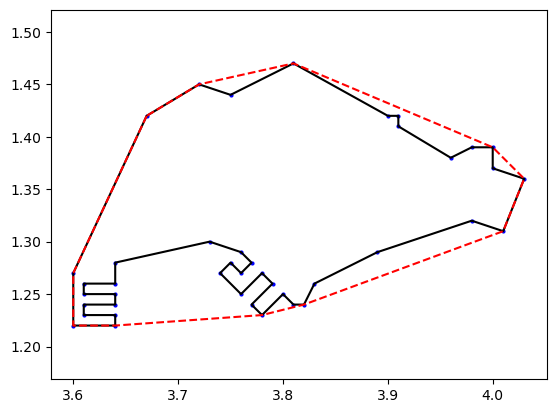

In [14]:
all_vertices = np.array([(3.81, 1.47), (3.75, 1.44), (3.72, 1.45), (3.67, 1.42), (3.60, 1.27), (3.60, 1.22),
                         (3.64, 1.22), (3.64, 1.23), (3.61, 1.23), (3.61, 1.24), (3.64, 1.24), (3.64, 1.25),
                         (3.61, 1.25), (3.61, 1.26), (3.64, 1.26), (3.64, 1.28), (3.73, 1.30), (3.76, 1.29),
                         (3.77, 1.28), (3.76, 1.27), (3.75, 1.28), (3.74, 1.27), (3.76, 1.25), (3.78, 1.27),
                         (3.79, 1.26), (3.77, 1.24), (3.78, 1.23), (3.80, 1.25), (3.81, 1.24), (3.82, 1.24),
                         (3.83, 1.26), (3.89, 1.29), (3.98, 1.32), (4.01, 1.31), (4.03, 1.36), (4.00, 1.37),
                         (4.00, 1.39), (3.98, 1.39), (3.96, 1.38), (3.91, 1.41), (3.91, 1.42), (3.90, 1.42)])

hull = ConvexHull(all_vertices)
num_vert, num_hull_vert = len(all_vertices), len(hull.vertices)

boundary = list(np.append(hull.vertices, hull.vertices[0]))
plt.plot(all_vertices[:, 0], all_vertices[:, 1], 'bo', ms = 2)
plt.plot(np.append(all_vertices[:, 0], all_vertices[0, 0]), np.append(all_vertices[:, 1], all_vertices[0, 1]), 'k')
plt.plot(all_vertices[boundary, 0], all_vertices[boundary, 1], 'r--')

plt.axis('equal')
plt.show()

In [ ]:
## What we had above was
## if inside((x_rand, y_rand), boundary) and not any([inside((x_rand, y_rand), i) for i in concaves]):

In [15]:
import numpy as np
from scipy.spatial import ConvexHull

class Polygon:
    def __init__(self, vertices):
        self.vertices = vertices.copy()
        self.num_vert = len(self.vertices)
        self.hull = ConvexHull(self.vertices)
        self.num_hull_vert = len(self.hull.vertices)
        self.boundary = np.append(self.hull.vertices, self.hull.vertices[0])
        self.concaves = []
        for i in range(self.num_hull_vert):
            if (self.boundary[i] + 1) % self.num_vert != self.boundary[i+1]:
                concave = [self.boundary[i]]
                j = self.boundary[i+1]
                while j != self.boundary[i]:
                    concave.append(j)
                    j = (j - 1) % self.num_vert
                self.concaves.append(Polygon(self.vertices[concave,:]))

In [16]:
island = Polygon(all_vertices)

In [ ]:
def determinant(px, p_fr, p_to):
    return px[0] * p_fr[1] + p_fr[0] * p_to[1] + p_to[0] * px[1] - px[1] * p_fr[0] - p_fr[1] * p_to[0] - p_to[1] * px[0]

def left_of_line(px, p_fr, p_to):
    return True if determinant(px, p_fr, p_to) > 0.0 else False

def inside_convex_hull(self, px):
    return all([left_of_line(px, self.vertices[self.boundary[i]], self.vertices[self.boundary[i+1]]) for i in range(self.num_hull_vert)])
    # is_inside = True if left_of_line is true for ALL line segments

def inside_polygon(self, px):
    return inside_convex_hull(self, px) and not any([inside_polygon(i, px) for i in self.concaves])
    # inside polygon if it is inside the convex hull, and not inside any concave void

## Now, we apply inside_polygon for EACH of the concave, so we can deal with complicated concaves

Polygon.inside_convex_hull = inside_convex_hull
Polygon.inside_polygon = inside_polygon
# define class methods outsdie class defintion


In [18]:
x_min, x_max = min(all_vertices[:, 0]), max(all_vertices[:, 0])
y_min, y_max = min(all_vertices[:, 1]), max(all_vertices[:, 1])

import random
random.seed('20240829')
count_inside, total_sample = 0, 10000
for _ in range(total_sample):
    x_rand, y_rand = x_min + random.random() * (x_max - x_min), y_min + random.random() * (y_max - y_min)
    if island.inside_polygon((x_rand, y_rand)):
        count_inside += 1

print('the estimated area is %.3f km square.' % (count_inside / total_sample * (x_max - x_min) * (y_max - y_min) * 12309.1))

the estimated area is 684.109 km square.


### Exercise 9-2.1: Scatter plot points inside, verify if points are all within the island outline.
### Exercise 9-2.2: What if there are other islands?

In [19]:
x_min, x_max = min(all_vertices[:, 0]), max(all_vertices[:, 0])
y_min, y_max = min(all_vertices[:, 1]), max(all_vertices[:, 1])

import random
random.seed('20261028')
count_inside, total_sample = 0, 3000
point_inside, point_outside = [], []
for _ in range(total_sample):
    x_rand, y_rand = x_min + random.random() * (x_max - x_min), y_min + random.random() * (y_max - y_min)
    if island.inside_polygon((x_rand, y_rand)):
        count_inside += 1
        point_inside.append((x_rand, y_rand))
    else:
        point_outside.append((x_rand, y_rand))

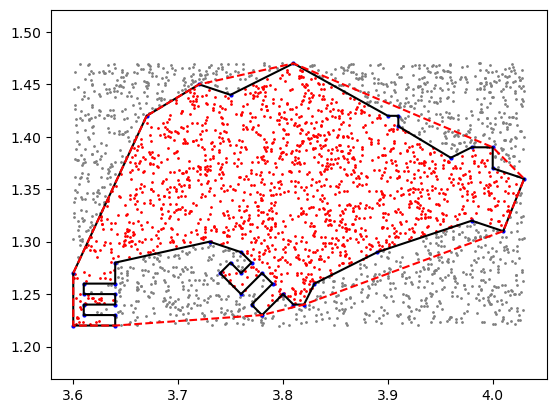

In [20]:
import matplotlib.pyplot as plt

plt.scatter([i[0] for i in point_inside], [i[1] for i in point_inside], s = 1, c = 'r')
plt.scatter([i[0] for i in point_outside], [i[1] for i in point_outside], s = 1, c = '0.5')

hull = ConvexHull(all_vertices)
num_vert, num_hull_vert = len(all_vertices), len(hull.vertices)

boundary = list(np.append(hull.vertices, hull.vertices[0]))
plt.plot(all_vertices[:, 0], all_vertices[:, 1], 'bo', ms = 2)
plt.plot(np.append(all_vertices[:, 0], all_vertices[0, 0]), np.append(all_vertices[:, 1], all_vertices[0, 1]), 'k')
plt.plot(all_vertices[boundary, 0], all_vertices[boundary, 1], 'r--')

plt.axis('equal')
plt.show()

In [ ]:
## wooclap

def func(a, b):
    while b:
        temp = b
        b = a % b
        a = temp
    return a

# print(func(12, 18))

a, b = 12, 18

while b:
    temp = b
    b = a % b
    a = temp
print(a)

##   b         a      temp
##   18        12     
##                    18
##   12%18=12  18     
##                    12
##   18%12=6   12     
##                    6
##   12%6=0    6
##   now we exit the while-loop


6


In [89]:
print(func(36, 24))

12


## Exercise 9-3: Portfolio Management

In [21]:
# if econ grow is x%
# stock index Gauss (2.2 * e^{0.4x} - 2, 0.4 * e^{0.4x})
# bond index uniform [x + 0.2 * e^{0.2x}, x + 0.8 * e^{0.2x}]

import time, random
random.seed('20240906')

growth = [random.uniform(1, 4) for _ in range(5)]
print('growth in percentage can be:', growth)

growth in percentage can be: [2.904548575937395, 3.589602858912191, 2.874832870117162, 3.157285657906279, 2.979361499340459]


In [22]:
import math
si = [random.gauss(2.2 * math.exp(0.4*x) - 2.0, 0.4 * math.exp(0.4*x)) for x in growth]      # generate stock index return per year, based on growth
bi = [random.uniform(x + 0.2 * math.exp(0.2*x), x + 0.8 * math.exp(0.2*x)) for x in growth]  # generate bond index return per year, based on growth
print('return of stock index in percentage:', si)
print('return of bond index in percentage:', bi)
print('which one has more significant volatility?')

return of stock index in percentage: [4.461151239965218, 10.280889893041154, 7.422496676644885, 6.7393450770663765, 3.209336741325246]
return of bond index in percentage: [3.3108057384166085, 4.054121520878897, 3.5692826600716603, 3.8354507058505423, 3.9481447583252813]
which one has more significant volatility?


In [92]:
# Given these stock returns [4.4, 10.2, 7.4, 6.7, 3.2]
s_portfolio = 1.044 * 1.102 * 1.074 * 1.067 * 1.032
s_portfolio

1.3606000771841282

In [93]:
def generate_return(num_year):
    growth = [random.uniform(1, 4) for _ in range(num_year)]
    si = [random.gauss(2.2 * math.exp(0.4*x) - 2.0, 0.4 * math.exp(0.4*x)) for x in growth]
    bi = [random.uniform(x + 0.2 * math.exp(0.2*x), x + 0.8 * math.exp(0.2*x)) for x in growth] # both si and bi are generated under the same econ conditions
    sr, br = 1.0, 1.0
    for i in range(num_year):
        sr *= (1.0 + si[i] / 100)
        br *= (1.0 + bi[i] / 100)
    return sr - 1, br - 1

In [94]:
generate_return(5)

(0.19512803516315214, 0.15470908436378772)

In [24]:
num_year, num_trial = 5, 10000
sr_pctg, br_pctg = [], []
sum_sr, sum_br, sum_sr_sq, sum_br_sq = 0.0, 0.0, 0.0, 0.0
for _ in range(num_trial):
    sr, br = generate_return(num_year)
    sr_pctg.append(sr * 100)
    br_pctg.append(br * 100)
    sum_sr += sr
    sum_br += br
    sum_sr_sq += sr * sr
    sum_br_sq += br * br

# calculate basic statistics
mean_sr, mean_br = sum_sr / num_trial, sum_br / num_trial
print('stock index return (%d-years), mean: %.2f%%, std: %.2f%%' % (num_year, mean_sr * 100, (sum_sr_sq / num_trial - mean_sr ** 2) ** 0.5 * 100))
print('bond index return (%d-years), mean: %.2f%%, std: %.2f%%' % (num_year, mean_br * 100, (sum_br_sq / num_trial - mean_br ** 2) ** 0.5 * 100))

stock index return (5-years), mean: 23.74%, std: 6.60%
bond index return (5-years), mean: 17.85%, std: 2.67%


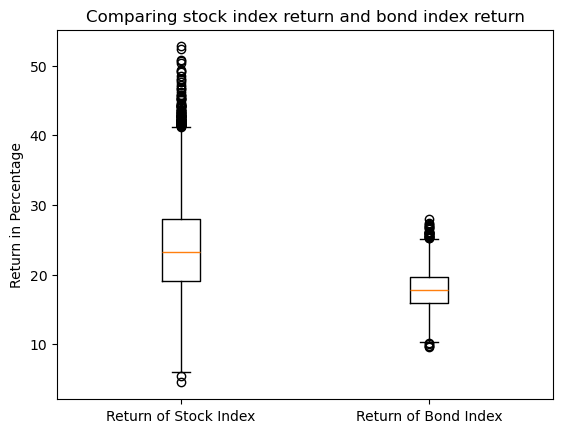

In [25]:
# plot the set of stock index return and the set of bond index return

import matplotlib.pyplot as plt

plt.boxplot([sr_pctg, br_pctg], labels = ['Return of Stock Index', 'Return of Bond Index'])

plt.title('Comparing stock index return and bond index return')
plt.ylabel('Return in Percentage')

plt.show()

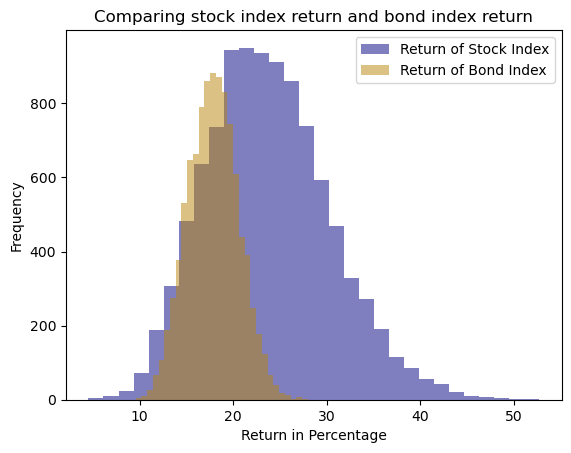

In [26]:
import matplotlib.pyplot as plt

plt.hist(sr_pctg, bins = 30, alpha = 0.5, label = 'Return of Stock Index', color = 'navy')
plt.hist(br_pctg, bins = 30, alpha = 0.5, label = 'Return of Bond Index', color = 'darkgoldenrod')

plt.title('Comparing stock index return and bond index return')
plt.xlabel('Return in Percentage')
plt.ylabel('Frequency')

plt.legend()
plt.show()

In [95]:
sr_pctg

[13.618910633217629,
 27.163335585749948,
 34.15614800811693,
 12.775702842688919,
 31.820555405725436,
 23.105729445340128,
 17.41938386776447,
 12.252487187126281,
 28.861504559405326,
 11.785731307093483,
 13.47985989995244,
 16.718537961528757,
 22.159474339812178,
 24.70057657011051,
 18.075835953811925,
 15.11022735055494,
 31.298910712748796,
 39.04175389477105,
 27.165421539324107,
 21.891523296283278,
 16.59996193078872,
 22.34559009001864,
 21.986954224287448,
 30.152380788054533,
 31.586567119183286,
 20.230867746902103,
 18.484835720495795,
 25.464014015655103,
 19.240326311849465,
 20.619930677527787,
 13.064082342506778,
 33.876008347384065,
 20.252949267305056,
 19.093205678000746,
 33.07847614062385,
 20.214052137150794,
 20.775888371263008,
 25.447740272790085,
 21.65257340934732,
 32.08423420364244,
 26.341683850575514,
 20.69277212293068,
 20.371709769936032,
 17.137612089316235,
 24.205278181379832,
 26.689273399074786,
 34.78206538443032,
 20.651915710663737,
 28.1

In [63]:
# What are the values of x, y, z, such that
# Pr(stock_index_return >= x) = 70%
# Pr(stock_index_return >= y) = 80%
# Pr(stock_index_return >= z) = 90%

import numpy as np

# Calculate the percentiles, caution: direction matters
percentile_sr, percentile_br = {}, {}
list_pctl = [60, 70, 80, 90, 95, 98, 99, 100]
for pctl in list_pctl:
    print('Percentile %ith' % (100-pctl))
    print('  -- Pr(stock_index_return >= %.2f%%) = %i%%' % (np.percentile(sr_pctg, 100 - pctl), pctl))
    print('  -- Pr(bond_index_return >= %.2f%%) = %i%%' % (np.percentile(br_pctg, 100 - pctl), pctl))

Percentile 40th
  -- Pr(stock_index_return >= 21.65%) = 60%
  -- Pr(bond_index_return >= 17.16%) = 60%
Percentile 30th
  -- Pr(stock_index_return >= 19.93%) = 70%
  -- Pr(bond_index_return >= 16.40%) = 70%
Percentile 20th
  -- Pr(stock_index_return >= 18.05%) = 80%
  -- Pr(bond_index_return >= 15.49%) = 80%
Percentile 10th
  -- Pr(stock_index_return >= 15.54%) = 90%
  -- Pr(bond_index_return >= 14.40%) = 90%
Percentile 5th
  -- Pr(stock_index_return >= 13.75%) = 95%
  -- Pr(bond_index_return >= 13.51%) = 95%
Percentile 2th
  -- Pr(stock_index_return >= 11.89%) = 98%
  -- Pr(bond_index_return >= 12.56%) = 98%
Percentile 1th
  -- Pr(stock_index_return >= 10.82%) = 99%
  -- Pr(bond_index_return >= 11.95%) = 99%
Percentile 0th
  -- Pr(stock_index_return >= 4.51%) = 100%
  -- Pr(bond_index_return >= 9.55%) = 100%


In [ ]:
amount_of_water_drank = [random.uniform(1000, 2500) for _ in range(100)]
sorted(amount_of_water_drank)

np.percentile(amount_of_water_drank, 10)   ## 10% drink this or less, 90% drink this or more

1138.170792988405

In [107]:
def func(n):
    row = [1]
    [row.append(row[i] * (n-i) // (i+1)) for i in range(n)]
    return row

## what we are returning is row, not the list comprehension
## .append is an inplace operation, so `row` will be updated


print(func(4))


[1, 4, 6, 4, 1]


In [ ]:
n = 4
holder = []
row = [1]
for i in range(n):
    holder.append(row.append(row[i] * (n-i) // (i+1)))

## row starts of with a list of 1 integer, and we perform append 4 times

print(row)

[1, 4, 6, 4, 1]


In [111]:
## this is equivalent to saying
row = [1]

i = 0
row.append(row[i] * (n-i) // (i+1))
i = 1
row.append(row[i] * (n-i) // (i+1))
i = 2
row.append(row[i] * (n-i) // (i+1))
i = 3
row.append(row[i] * (n-i) // (i+1))

print(row)


[1, 4, 6, 4, 1]


### Exercise 9-3.1

Calculate the target return with the portfolios at 60%, 70%, 80%, 90%, 95%, 98% and 100% confidence.

In [28]:
import numpy as np

ptfl_return, ptfl_pctl = {}, {k: {} for k in list_pctl}
for i in range(10, 100, 10):
    mix_return = []
    for j in range(num_trial):
        mix_return.append(i / 100 * sr_pctg[j] + (100 - i) / 100 * br_pctg[j])
    ptfl_return['s%i\nb%i' % (i, 100-i)] = mix_return
    for pctl in list_pctl:
        ptfl_pctl[pctl]['s%i+b%i' % (i, 100-i)] = np.percentile(mix_return, 100 - pctl)
for k, v in ptfl_pctl.items():
    print(k, v)

60 {'s10+b90': 17.632084781620115, 's20+b80': 18.112648530387425, 's30+b70': 18.5510803770823, 's40+b60': 18.993078711313668, 's50+b50': 19.432355932148525, 's60+b40': 19.879046520448316, 's70+b30': 20.327205516162294, 's80+b20': 20.762000602402697, 's90+b10': 21.211420555059274}
70 {'s10+b90': 16.810952041575394, 's20+b80': 17.195763386673093, 's30+b70': 17.562609053766906, 's40+b60': 17.917162666873224, 's50+b50': 18.263424392752, 's60+b40': 18.59893072862221, 's70+b30': 18.928349257825236, 's80+b20': 19.26390268642718, 's90+b10': 19.594519017002646}
80 {'s10+b90': 15.815123436077966, 's20+b80': 16.095851108672694, 's30+b70': 16.381964425359918, 's40+b60': 16.641392206196784, 's50+b50': 16.891626809486496, 's60+b40': 17.133222705470075, 's70+b30': 17.37987759278481, 's80+b20': 17.59580808451424, 's90+b10': 17.83031312989111}
90 {'s10+b90': 14.606835221050936, 's20+b80': 14.76968950655565, 's30+b70': 14.917258906824191, 's40+b60': 15.032407376113285, 's50+b50': 15.157177300616459, 's6

### Exercise 9-3.2

Boxplot the portfolios, and line plot the target return with the portfolios at 60%, 70%, 80%, 90%, 95%, 98% and 100%.

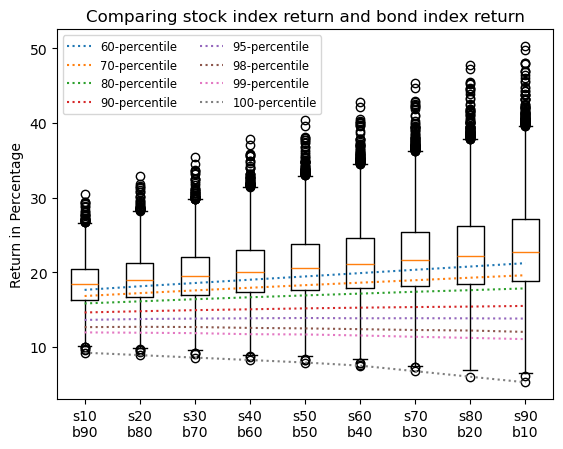

In [29]:
import matplotlib.pyplot as plt

plt.boxplot(ptfl_return.values(), labels = ptfl_return.keys())

for pctl in list_pctl:
    plt.plot(range(1, 10), ptfl_pctl[pctl].values(), ls = ':', label = '%i-percentile' % pctl)

plt.title('Comparing stock index return and bond index return')
plt.ylabel('Return in Percentage')

plt.legend(loc = 'upper left', ncol = 2, fontsize = 'small')
plt.show()

In [30]:
def func(n):
    row = [1]
    for i in range(n):
        row.append(row[i] * (n-i) // (i+1))
    return row

print(*func(4))


1 4 6 4 1


## Exercise 9-4: Performance Bonus

In [31]:
# Effort determines both
# good year or bad year
# starting 60,000, simulate for 5 years

import random
random.seed('20240912')

num_employ = 10
salary = [random.randint(6000000, 8000000) / 100 for _ in range(num_employ)]

# simulate 10 employees' salaries between 60000 and 80000

In [32]:
print(salary)

[68984.45, 67627.34, 75255.64, 70995.07, 77687.07, 61606.4, 75254.79, 77701.77, 60476.62, 72532.61]


In [33]:
possible_diligence = [0.1, 0.2, 0.3, 0.3, 0.4, 0.4, 0.4,
                      0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
                      0.6, 0.6, 0.6, 0.6, 0.7, 0.7, 0.7,
                      0.8, 0.8, 0.8, 0.9, 0.9, 1.0, 1.0]

diligence = random.sample(possible_diligence, num_employ)

print(diligence) # each person may have a different diligence level, some are more hard-working

[0.8, 0.4, 0.5, 1.0, 0.5, 0.1, 0.3, 0.9, 0.7, 0.4]


In [34]:
performance = [max(0.0, random.gauss(0.1 * p, 0.01 * p)) for p in diligence]
print('performance:', performance) # performance is determined by a random number in relation to his diligence
                                   # when diligence = 0.5, performance is a random number ~ Gauss(5%, 0.005), probably between 4% and 6%

performance: [0.0726674499836699, 0.039268352918244036, 0.03744699581627232, 0.11922569711006784, 0.05071739248966588, 0.01066579760995397, 0.023562400525155153, 0.08346892467254248, 0.06706572712634602, 0.036055353392899975]


In [35]:
# in a normal year, the year-end bonus is the salary multiplied by performance
print('\n'.join(['expected year-end bonus: %.2f' % (salary[i] * performance[i]) for i in range(num_employ)]))

expected year-end bonus: 5012.92
expected year-end bonus: 2655.61
expected year-end bonus: 2818.10
expected year-end bonus: 8464.44
expected year-end bonus: 3940.09
expected year-end bonus: 657.08
expected year-end bonus: 1773.18
expected year-end bonus: 6485.68
expected year-end bonus: 4055.91
expected year-end bonus: 2615.19


In [36]:
# however, some years are good, some years are more challenging, the year-end bonuses may grow or shrink
year_goodness = random.uniform(0.8, 1.2)
print('this year:', year_goodness)

this year: 1.068693725175431


In [37]:
print('adjusted by the year goodness:')
print('\n'.join(['    adjusted year-end bonus: %.2f' % (salary[i] * performance[i] * year_goodness) for i in range(num_employ)]))

adjusted by the year goodness:
    adjusted year-end bonus: 5357.28
    adjusted year-end bonus: 2838.04
    adjusted year-end bonus: 3011.68
    adjusted year-end bonus: 9045.89
    adjusted year-end bonus: 4210.74
    adjusted year-end bonus: 702.22
    adjusted year-end bonus: 1894.99
    adjusted year-end bonus: 6931.21
    adjusted year-end bonus: 4334.52
    adjusted year-end bonus: 2794.84


### Exercise 9-4.1: What if no one wants a year-end bonus and instead prefers to accumulate it as an annual increment?

In [38]:
orig_salary = salary.copy()
num_year = 5
performance = [[max(0.0, random.gauss(0.1 * p, 0.01 * p)) for p in diligence] for _ in range(num_year)]
year_goodness = [random.uniform(0.8, 1.2) for _ in range(num_year)]

In [39]:
def year_end_bonus(salary, performance, year_goodness): # calculating the year end bonus
    return [salary[i] * performance[i] * year_goodness for i in range(len(salary))]

def next_year_salary(salary, performance, year_goodness): # if year end bonus is added to the salary of the next year
    return [salary[i] * (1 + performance[i] * year_goodness) for i in range(len(salary))]

In [40]:
bonus_over_years = [year_end_bonus(orig_salary, perf, ygood) for (perf, ygood) in zip(performance, year_goodness)]
salary_over_years = [salary]
for i in range(num_year):
    salary = next_year_salary(salary, performance[i], year_goodness[i])
    salary_over_years.append(salary)
# we expect 5 elements in bonus_over_years but 6 elements in salary_over_years, why?

In [41]:
print('bonus over years (each row corresponds to a year, each column corresponds to an employee):')
print('\n'.join(['  ' + ', '.join(['%.2f' % j for j in i]) for i in bonus_over_years]))

bonus over years (each row corresponds to a year, each column corresponds to an employee):
  6636.09, 3179.00, 4347.84, 9237.57, 4462.80, 648.00, 2633.42, 8413.26, 4950.83, 3244.55
  6043.62, 2658.55, 3567.53, 6747.07, 4051.83, 624.43, 2062.85, 6719.15, 3967.51, 3096.75
  5563.67, 3297.36, 3800.55, 7182.71, 4723.77, 598.19, 2504.90, 5912.70, 4557.99, 2951.75
  5997.95, 2828.57, 3313.19, 6786.54, 3680.08, 605.69, 2255.38, 7026.75, 3560.33, 3182.19
  5495.72, 2928.72, 3755.68, 6954.79, 4764.76, 601.73, 1947.34, 7437.72, 4356.34, 2988.33


In [42]:
print('salary over years (each row corresponds to a year, each column corresponds to an employee):')
print('\n'.join(['  ' + ', '.join(['%.2f' % j for j in i]) for i in salary_over_years]))

salary over years (each row corresponds to a year, each column corresponds to an employee):
  68984.45, 67627.34, 75255.64, 70995.07, 77687.07, 61606.40, 75254.79, 77701.77, 60476.62, 72532.61
  75620.54, 70806.34, 79603.48, 80232.64, 82149.87, 62254.40, 77888.21, 86115.03, 65427.45, 75777.16
  82245.55, 73589.87, 83377.12, 87857.61, 86434.47, 62885.40, 80023.24, 93561.71, 69719.75, 79012.43
  88878.74, 77177.95, 87587.81, 96746.34, 91690.12, 63496.01, 82686.87, 100681.27, 74974.38, 82227.89
  96606.43, 80405.98, 91443.93, 105994.48, 96033.53, 64120.27, 85164.99, 109786.11, 79388.21, 85835.43
  104302.68, 83888.10, 96007.50, 116377.87, 101923.53, 64746.56, 87368.76, 120295.00, 85106.81, 89371.84


In [43]:
discount_rate = 0.1 # a pretty high discount rate: what you can buy with 10 dollar this year is what you can buy with 11 dollar next year
curr_value_bonus = [0.0] * num_employ
for i in range(num_employ):
    for j in range(num_year):
        curr_value_bonus[i] += bonus_over_years[j][i] / (1 + discount_rate) ** j # calculate the current value as the end of the first year
print(curr_value_bonus)

[24988.371286228303, 12446.463136102082, 15786.421022799299, 31156.437646227823, 18069.520086139066, 2576.087013733274, 9603.460755943403, 29767.481845826893, 17974.95627192006, 12931.1420049345]


In [44]:
curr_value_incr = [0.0] * num_employ
for i in range(num_employ):
    for j in range(1, num_year+1):
        for k in range(12):
            curr_value_incr[i] += (salary_over_years[j][i] - salary_over_years[0][i]) / 12 / (1 + discount_rate / 12) ** (12 * j + k - 11)
                  # 12 * j + k - 11 is the number of months after the end of the first year
print(curr_value_incr)

[75018.56189747417, 34880.53522846442, 45256.86166735248, 96716.02791590139, 50935.73008229388, 6945.240056234276, 27037.48181406631, 89096.70181001142, 52855.82887706386, 36235.58814965576]


In [45]:
sorted(list(zip(diligence, orig_salary, curr_value_bonus, curr_value_incr)))

[(0.1, 61606.4, 2576.087013733274, 6945.240056234276),
 (0.3, 75254.79, 9603.460755943403, 27037.48181406631),
 (0.4, 67627.34, 12446.463136102082, 34880.53522846442),
 (0.4, 72532.61, 12931.1420049345, 36235.58814965576),
 (0.5, 75255.64, 15786.421022799299, 45256.86166735248),
 (0.5, 77687.07, 18069.520086139066, 50935.73008229388),
 (0.7, 60476.62, 17974.95627192006, 52855.82887706386),
 (0.8, 68984.45, 24988.371286228303, 75018.56189747417),
 (0.9, 77701.77, 29767.481845826893, 89096.70181001142),
 (1.0, 70995.07, 31156.437646227823, 96716.02791590139)]

In [46]:
print('diligence\torig_salary\tye_bonus\tannual_incr')
print('\n'.join(map(lambda x: '\t'.join(map(lambda y: '%8.2f' % y, x)), sorted(list(zip(diligence, orig_salary, curr_value_bonus, curr_value_incr))))))

diligence	orig_salary	ye_bonus	annual_incr
    0.10	61606.40	 2576.09	 6945.24
    0.30	75254.79	 9603.46	27037.48
    0.40	67627.34	12446.46	34880.54
    0.40	72532.61	12931.14	36235.59
    0.50	75255.64	15786.42	45256.86
    0.50	77687.07	18069.52	50935.73
    0.70	60476.62	17974.96	52855.83
    0.80	68984.45	24988.37	75018.56
    0.90	77701.77	29767.48	89096.70
    1.00	70995.07	31156.44	96716.03


In [47]:
curr_value_incr = [0.0] * num_employ
for i in range(num_employ):
    for j in range(1, num_year+1):
        for k in range(12):
            curr_value_incr[i] += (salary_over_years[j][i] - salary_over_years[j-1][i]) / 12 / (1 + discount_rate / 12) ** (12 * j - 11 + k)
print(curr_value_incr)

[27457.94227768572, 12674.197844185837, 16245.103379949971, 35312.87441964616, 18790.893605262696, 2467.391679003176, 9541.775522192102, 32983.55987194049, 19199.727553921086, 13135.901076809612]


In [48]:
print('diligence\torig_salary\tye_bonus\tannual_incr')
print('\n'.join(map(lambda x: '\t'.join(map(lambda y: '%8.2f' % y, x)), sorted(list(zip(diligence, orig_salary, curr_value_bonus, curr_value_incr))))))

diligence	orig_salary	ye_bonus	annual_incr
    0.10	61606.40	 2576.09	 2467.39
    0.30	75254.79	 9603.46	 9541.78
    0.40	67627.34	12446.46	12674.20
    0.40	72532.61	12931.14	13135.90
    0.50	75255.64	15786.42	16245.10
    0.50	77687.07	18069.52	18790.89
    0.70	60476.62	17974.96	19199.73
    0.80	68984.45	24988.37	27457.94
    0.90	77701.77	29767.48	32983.56
    1.00	70995.07	31156.44	35312.87


### Exercise 9-4.2: What if one resignes after x years and y months?

In [49]:
resign = [(random.randint(1, 5), random.randrange(12)) for _ in range(num_employ)]
# random.randint(1, 5): include both 1 and 5
# random.randrange(12) # works like a range, does not include 12

In [50]:
print(resign)

[(3, 0), (5, 4), (2, 3), (5, 8), (1, 3), (3, 10), (4, 6), (3, 8), (4, 9), (4, 4)]


In [51]:
curr_value_bonus = [0.0] * num_employ
for i in range(num_employ):
    for j in range(resign[i][0]):
        curr_value_bonus[i] += bonus_over_years[j][i] / (1 + discount_rate) ** j
print(curr_value_bonus)

[16728.37517017574, 12446.463136102082, 7591.044415558343, 31156.437646227823, 4462.8029837871645, 1710.035365996161, 8273.403566274912, 19408.11485849483, 14999.519826846401, 10890.069599931672]


In [52]:
curr_value_incr = [0.0] * num_employ
for i in range(num_employ):
    for j in range(1, resign[i][0]+1):
        for k in range(12 if j < resign[i][0] else resign[i][1]): # special case for the last year
            curr_value_incr[i] += (salary_over_years[j][i] - salary_over_years[j-1][i]) / 12 / (1 + discount_rate / 12) ** (12 * j + k - 11)
print(curr_value_incr)

[11974.634707235411, 11221.421291940323, 4961.159181442411, 33182.797422631156, 1097.360806524602, 1554.0966657209503, 7289.744943882479, 18111.53113158949, 14813.126000929864, 9222.502307524719]


In [53]:
sorted(list(zip(diligence, orig_salary, resign, curr_value_bonus, curr_value_incr)))

[(0.1, 61606.4, (3, 10), 1710.035365996161, 1554.0966657209503),
 (0.3, 75254.79, (4, 6), 8273.403566274912, 7289.744943882479),
 (0.4, 67627.34, (5, 4), 12446.463136102082, 11221.421291940323),
 (0.4, 72532.61, (4, 4), 10890.069599931672, 9222.502307524719),
 (0.5, 75255.64, (2, 3), 7591.044415558343, 4961.159181442411),
 (0.5, 77687.07, (1, 3), 4462.8029837871645, 1097.360806524602),
 (0.7, 60476.62, (4, 9), 14999.519826846401, 14813.126000929864),
 (0.8, 68984.45, (3, 0), 16728.37517017574, 11974.634707235411),
 (0.9, 77701.77, (3, 8), 19408.11485849483, 18111.53113158949),
 (1.0, 70995.07, (5, 8), 31156.437646227823, 33182.797422631156)]

In [54]:
print('diligence\torig_salary\tresign after\tye_bonus\tannual_incr')
print('\n'.join(map(lambda x: '\t'.join(map(lambda y: '%8.2f' % y if type(y) == float else '%d yrs %i mth' % y, x)),
                    sorted(list(zip(diligence, orig_salary, resign, curr_value_bonus, curr_value_incr))))))

diligence	orig_salary	resign after	ye_bonus	annual_incr
    0.10	61606.40	3 yrs 10 mth	 1710.04	 1554.10
    0.30	75254.79	4 yrs 6 mth	 8273.40	 7289.74
    0.40	67627.34	5 yrs 4 mth	12446.46	11221.42
    0.40	72532.61	4 yrs 4 mth	10890.07	 9222.50
    0.50	75255.64	2 yrs 3 mth	 7591.04	 4961.16
    0.50	77687.07	1 yrs 3 mth	 4462.80	 1097.36
    0.70	60476.62	4 yrs 9 mth	14999.52	14813.13
    0.80	68984.45	3 yrs 0 mth	16728.38	11974.63
    0.90	77701.77	3 yrs 8 mth	19408.11	18111.53
    1.00	70995.07	5 yrs 8 mth	31156.44	33182.80


### Exercise 9-4.3: How should one distribute year-end bonus versus annual increment?

In [55]:
def year_end_bonus(salary, performance, year_goodness, ratio):
    return [salary[i] * performance[i] * year_goodness * ratio for i in range(len(salary))]

def next_year_salary(salary, performance, year_goodness, ratio):
    return [salary[i] * (1 + performance[i] * year_goodness * ratio) for i in range(len(salary))]
# modify the two functions above, we can allocate year_end_bonus and next_year_salary in the ratio of 40%-60% 

In [56]:
def total_reward(bonus_ratio, discount_rate): # now write a function for total reward, bonus + annual increment
    salary = orig_salary.copy()
    bonus_over_years = [year_end_bonus(orig_salary, perf, ygood, bonus_ratio) for (perf, ygood) in zip(performance, year_goodness)]
    salary_over_years = [salary]
    for i in range(num_year):
        salary = next_year_salary(salary, performance[i], year_goodness[i], 1 - bonus_ratio)
        salary_over_years.append(salary)
    curr_value = [0.0] * num_employ
    for i in range(num_employ):
        for j in range(num_year):
            curr_value[i] += bonus_over_years[j][i] / (1 + discount_rate) ** j
    # above curr_value are from year_end_bonus
    # below are curr_value accumulated from salary increment
    for i in range(num_employ):
        for j in range(1, num_year+1):
            for k in range(12):
                curr_value[i] += (salary_over_years[j][i] - salary_over_years[j-1][i]) / 12 / (1 + discount_rate / 12) ** (12 * j + k - 11)
    return curr_value

In [57]:
bonus_ratio = 0.0
matrix_total_reward = [] # each row corresponds to one mixture from bonus and annual increment, each column coresponds to one employee
while bonus_ratio <= 1.0:
    matrix_total_reward.append(total_reward(bonus_ratio, 0.1))
    bonus_ratio += 0.1

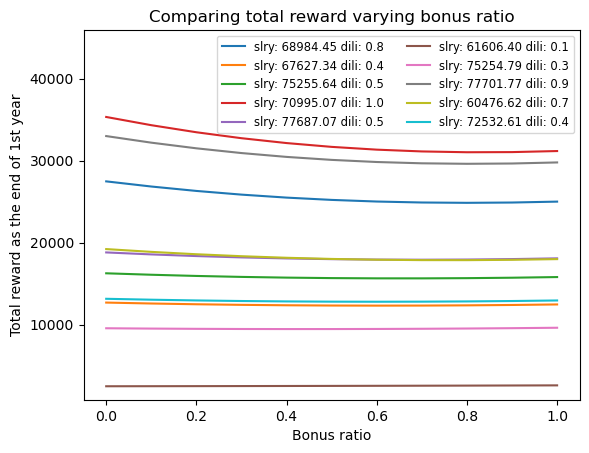

In [58]:
import matplotlib.pyplot as plt

for i in range(num_employ):
    plt.plot([t / 10 for t in range(0, 11)], [t[i] for t in matrix_total_reward], label = 'slry: %.2f dili: %.1f' % (orig_salary[i], diligence[i]))

plt.title('Comparing total reward varying bonus ratio')
plt.xlabel('Bonus ratio')
plt.ylabel('Total reward as the end of 1st year')

plt.gca().set_ylim(top = int(max(map(max, matrix_total_reward)) * 1.3))
plt.legend(loc = 'upper right', ncol = 2, fontsize = 'small')
plt.show()

In [59]:
print('\n'.join(['\t'.join(['%8.2f' % j for j in i]) for i in matrix_total_reward]))

27457.94	12674.20	16245.10	35312.87	18790.89	 2467.39	 9541.78	32983.56	19199.73	13135.90
26829.90	12561.22	16068.72	34310.90	18549.53	 2474.27	 9501.33	32179.46	18859.15	13024.81
26291.82	12468.95	15922.41	33448.89	18347.31	 2482.04	 9471.47	31489.63	18569.53	12934.50
25841.69	12397.12	15805.76	32723.10	18183.65	 2490.71	 9452.12	30911.35	18329.91	12864.71
25477.48	12345.49	15718.37	32129.84	18057.97	 2500.26	 9443.18	30441.95	18139.35	12815.22
25197.23	12313.83	15659.84	31665.53	17969.69	 2510.69	 9444.57	30078.80	17996.92	12785.78
24999.00	12301.88	15629.78	31326.61	17918.24	 2522.02	 9456.21	29819.29	17901.70	12776.15
24880.86	12309.41	15627.79	31109.62	17903.05	 2534.22	 9478.00	29660.89	17852.78	12786.11
24840.94	12336.17	15653.49	31011.15	17923.57	 2547.30	 9509.86	29601.09	17849.27	12815.41
24877.38	12381.93	15706.49	31027.84	17979.24	 2561.26	 9551.71	29637.43	17890.29	12863.83
24988.37	12446.46	15786.42	31156.44	18069.52	 2576.09	 9603.46	29767.48	17974.96	12931.14


### Exercise 9-4.4: Shall we work consistently hard?

In [60]:
orig_salary = [j for i in list(zip(orig_salary[:5], orig_salary[:5])) for j in i]
# fix starting salary for each pair
performance = [[0.0] * num_employ for _ in range(5)]
for i in range(num_employ):
    if i % 2 == 0:
        for j in range(5):
            performance[j][i] = max(0.0, random.gauss(0.07, 0.007))
        # consistent mode for i being an even integer
    else:
        for j in range(2):
            performance[j][i] = max(0.0, random.gauss(0.1, 0.01))
        for j in range(2, 5):
            performance[j][i] = max(0.0, random.gauss(0.05, 0.005))
        # inconsistent mode for i being an odd integer

def total_reward(bonus_ratio, discount_rate):
    salary = orig_salary.copy()
    bonus_over_years = [year_end_bonus(orig_salary, perf, ygood, bonus_ratio) for (perf, ygood) in zip(performance, year_goodness)]
    salary_over_years = [salary]
    for i in range(num_year):
        salary = next_year_salary(salary, performance[i], year_goodness[i], 1 - bonus_ratio)
        salary_over_years.append(salary)
    curr_value = [0.0] * num_employ
    for i in range(num_employ):
        for j in range(num_year):
            curr_value[i] += bonus_over_years[j][i] / (1 + discount_rate) ** j
    for i in range(num_employ):
        for j in range(1, num_year+1):
            for k in range(12):
                curr_value[i] += (salary_over_years[j][i] - salary_over_years[j-1][i]) / 12 / (1 + discount_rate / 12) ** (12 * j + k - 11)
    return curr_value

In [61]:
bonus_ratio = 0.0
matrix_total_reward = [] # each row corresponds to one mixture from bonus and annual increment, each column coresponds to one employee
while bonus_ratio <= 1.0:
    matrix_total_reward.append(total_reward(bonus_ratio, 0.1))
    bonus_ratio += 0.1

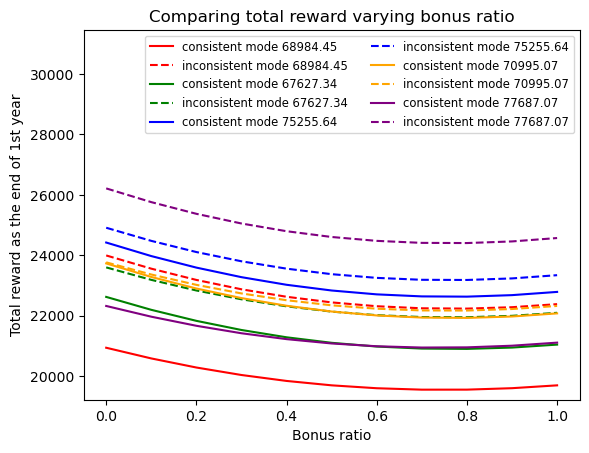

In [62]:
import matplotlib.pyplot as plt
line_color = ['red', 'green', 'blue', 'orange', 'purple']

for i in range(num_employ):
    if i % 2 == 0:
        plt.plot([t / 10 for t in range(0, 11)], [t[i] for t in matrix_total_reward], ls = '-', c = line_color[i//2], label = 'consistent mode %.2f' % orig_salary[i])
    else:
        plt.plot([t / 10 for t in range(0, 11)], [t[i] for t in matrix_total_reward], ls = '--', c = line_color[i//2], label = 'inconsistent mode %.2f' % orig_salary[i])

plt.title('Comparing total reward varying bonus ratio')
plt.xlabel('Bonus ratio')
plt.ylabel('Total reward as the end of 1st year')

plt.gca().set_ylim(top = int(max(map(max, matrix_total_reward)) * 1.2))
plt.legend(loc = 'upper right', ncol = 2, fontsize = 'small')
plt.show()